# Active learning, one acquisition at a time
### A CPU-only training-school laboratory using handwritten digits

**What you will build:** a reproducible pool-based active-learning experiment with a classifier, scoring policy, acquisition budget, oracle, pool state, and validation history. The goal is not to maximize accuracy at any cost; it is to learn how to choose **which labels to request**.

**Core laboratory (~75–100 minutes):** understand splits and a tiny labeled baseline, calculate uncertainty, query a simulated oracle, run complete cycles, then compare acquisition policies. **Exercises:** implement scoring, vary batch sizes, repeat paired initial seeds, and add diversity. The optional experiments require additional CPU fitting time.

**Everything runs on a CPU, completely offline.** We use the built-in scikit-learn digits dataset and the *actual* \`al_pipeline.core\` interfaces. The science-specific astronomical adapters are not needed.

> **Important distinction:** The model must never see labels from the unlabeled candidate pool. The benchmark stores those labels *only* so a simulated oracle can reveal them after a selection. We tune policies against a fixed validation split and reserve the held-out test split for one final evaluation.


## 1. The experimental question and the four data populations

In standard supervised learning, we start with labels for all training objects. In active learning, we start with a small labeled set $L_0$ and a larger unlabeled candidate pool $U_0$. At cycle $t$:

1. Train a model on **observed** labels in $L_t$.
2. Predict class probabilities for the eligible objects in $U_t$.
3. Rank candidates using an acquisition policy (random, entropy, margin, ...).
4. Select a batch $B_t$, request labels from an **oracle**, and update the pool.
5. Retrain and measure validation performance at the same cumulative label budget.

We also keep a **validation** split for comparisons and a **sealed test** split for a final evaluation. Neither is ever an acquisition candidate.

The key question is: **with the same initial labels and acquisition budget, does the choice of queried objects improve classification?** A result on one seed is not conclusive.


In [1]:
# All dependencies are CPU-friendly. Run from an editable installation:
#     python -m pip install -e ".[teaching]"
#
# TODO 1/2 are deliberately incomplete in the participant notebook.
# Enable their assertions only after filling in the functions.
# Optional experiments (TODO 3–5) can be run without completing TODO 1/2.
RUN_EXERCISES = False
RUN_OPTIONAL_EXPERIMENTS = False

# Force embedded notebook figures even when a headless CPU runner sets
# MPLBACKEND=Agg. This is executed inside IPython/Jupyter, not plain Python.
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from al_pipeline.core.batch_selection import DiversitySelector
from al_pipeline.core.evaluation.history import EvaluationHistory
from al_pipeline.core.evaluation.metrics import compute_classification_metrics
from al_pipeline.core.evaluation.plotting import plot_strategy_comparison
from al_pipeline.core.evaluation.notebook_style import (
    use_notebook_style, policy_color, polish_policy_axes
)
from al_pipeline.core.loop import ActiveLearningLoop
from al_pipeline.core.oracle.existing_labels import ExistingLabelsOracle
from al_pipeline.core.pool import Pool
from al_pipeline.core.scoring.entropy import EntropyScorer
from al_pipeline.core.scoring.margin import MarginScorer
from al_pipeline.core.scoring.random import RandomScorer
from al_pipeline.core.selection import TopKSelector
from al_pipeline.core.types import ClassificationPredictions

# Optional visual theme: comment this call out to use ordinary Matplotlib.
use_notebook_style()

SEED = 2026
INITIAL_PER_CLASS = 5
BATCH_SIZE = 20
N_CYCLES = 8
CLASS_LABELS = tuple(range(10))
METRICS = ("accuracy", "balanced_accuracy", "f1_macro")
print("CPU-only notebook configuration:", dict(seed=SEED, initial=50,
      batch=BATCH_SIZE, cycles=N_CYCLES))


CPU-only notebook configuration: {'seed': 2026, 'initial': 50, 'batch': 20, 'cycles': 8}


## 2. Inspect the real images (no downloads)

Scikit-learn ships 1,797 grayscale digit images. Each is only **8×8 pixels**: expressive enough for a real multiclass classification task and small enough that a linear model trains quickly.

The image is the feature input. A label such as “7” is *ground truth* that the training model may access **only after** it belongs to the labeled pool. The split is made once so every acquisition policy gets the same task.


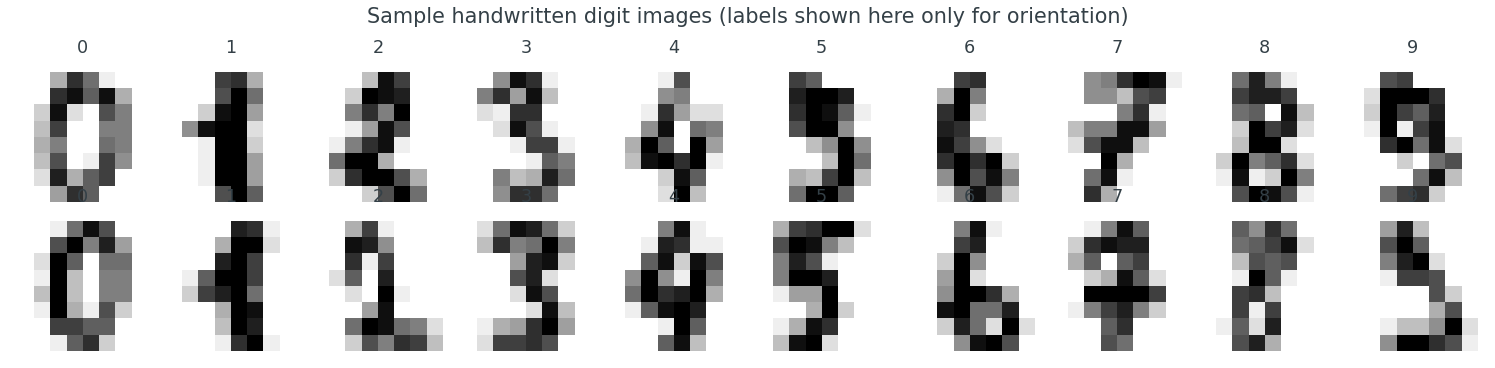

In [2]:
digits = load_digits()
images = np.asarray(digits.images, dtype=float)
X = np.asarray(digits.data, dtype=float) / 16.0  # pixels scaled to [0, 1]
y = np.asarray(digits.target, dtype=int)
all_ids = np.asarray([f"digit-{i:04d}" for i in range(len(y))], dtype=object)
id_to_index = {object_id: i for i, object_id in enumerate(all_ids)}
assert images.shape[1:] == (8, 8)
assert X.shape[1] == 64 and set(np.unique(y)) == set(CLASS_LABELS)

fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for ax, i in zip(axes.flat, range(20)):
    ax.imshow(images[i], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(str(y[i]))
    ax.axis("off")
fig.suptitle("Sample handwritten digit images (labels shown here only for orientation)")
plt.tight_layout()
plt.show()


In [3]:
# Stratified, disjoint splits: 60% candidate/training population,
# 20% validation, and 20% sealed final test.
indices = np.arange(len(y))
pool_indices, test_indices = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEED,
)
pool_indices, val_indices = train_test_split(
    pool_indices, test_size=0.25, stratify=y[pool_indices], random_state=SEED,
)
pool_indices = np.sort(pool_indices)
val_indices = np.sort(val_indices)
test_indices = np.sort(test_indices)
assert len(set(pool_indices) & set(val_indices)) == 0
assert len(set(pool_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0
assert len(pool_indices) + len(val_indices) + len(test_indices) == len(y)

pool_ids = all_ids[pool_indices].tolist()
print(f"Candidate/training population: {len(pool_indices)} images")
print(f"Fixed validation split: {len(val_indices)} images")
print(f"Sealed test split: {len(test_indices)} images")


Candidate/training population: 1077 images
Fixed validation split: 360 images
Sealed test split: 360 images


### Construct $L_0$: our first fifty labels

We select **five labeled digits per class**. For this controlled benchmark only, the dataset's existing labels are used to create that balanced initial seed. In a real scientific problem, an initial labeled catalog or a separate labeling campaign would be required.

All other candidate labels remain hidden in an \`ExistingLabelsOracle\`. The training code below uses a separate \`observed_labels\` dictionary, and the oracle is called **only for selected objects**. This separation is more meaningful than simply remembering not to inspect the labels.


In [4]:
def balanced_initial_population(initial_seed):
    """Choose five observed seed labels per class, reproducibly.

    The reference dataset's labels are consulted ONLY to construct a balanced
    teaching benchmark seed; this helper is never called by the AL scorer.
    """
    rng = np.random.default_rng(initial_seed)
    chosen_indices = np.sort(np.concatenate([
        rng.choice(pool_indices[y[pool_indices] == digit],
                   size=INITIAL_PER_CLASS, replace=False)
        for digit in CLASS_LABELS
    ]))
    chosen_ids = [str(all_ids[i]) for i in chosen_indices]
    chosen_labels = {str(all_ids[i]): int(y[i]) for i in chosen_indices}
    return chosen_ids, chosen_labels


initial_ids, initial_labels = balanced_initial_population(SEED)

# The simulated oracle holds all candidate labels, but the model never
# receives this mapping. Only oracle.query(selection) reveals new ones.
oracle = ExistingLabelsOracle({
    str(all_ids[i]): int(y[i]) for i in pool_indices
})
baseline_pool = Pool.from_ids(pool_ids, labeled_ids=initial_ids)
assert len(initial_labels) == 50
assert len(baseline_pool.labeled_ids) == 50
assert len(baseline_pool.unlabeled_ids) == len(pool_indices) - 50
assert len(baseline_pool.pending_ids) == 0
print("Initial labeled distribution:",
      pd.Series(list(initial_labels.values())).value_counts().sort_index().to_dict())
print("L0:", len(baseline_pool.labeled_ids), "U0:", len(baseline_pool.unlabeled_ids))

Initial labeled distribution: {0: 5, 1: 5, 2: 5, 3: 5, 4: 5, 5: 5, 6: 5, 7: 5, 8: 5, 9: 5}
L0: 50 U0: 1027


## 3. Train and evaluate an intentionally modest model

For clarity we use **multinomial logistic regression** rather than a neural network. It predicts a full ten-class probability vector and fits quickly on a CPU. We retrain a fresh instance at each cycle, using the same settings and the cumulative observed labels.

This toy classifier is **not** an AstroMiNN architecture. The *active-learning infrastructure* is shared; the learning model is deliberately replaceable.

Our primary metrics are macro-F1 (treats classes equally), balanced accuracy (average recall across classes), and ordinary accuracy. We evaluate only on the fixed validation split while developing acquisition policies.


In [5]:
def fit_model(observed_labels):
    """Train from scratch on exactly the labels revealed to this run."""
    ids = sorted(observed_labels)
    rows = np.asarray([id_to_index[object_id] for object_id in ids], dtype=int)
    targets = np.asarray([observed_labels[object_id] for object_id in ids], dtype=int)
    model = LogisticRegression(C=1.0, max_iter=500, solver="lbfgs")
    model.fit(X[rows], targets)
    assert np.array_equal(model.classes_, np.asarray(CLASS_LABELS))
    return model


def evaluate_validation(model):
    predictions = ClassificationPredictions(
        values=model.predict_proba(X[val_indices]),
        output_type="probabilities",
    )
    return compute_classification_metrics(
        y[val_indices], predictions, metrics=METRICS, labels=CLASS_LABELS,
    )


baseline_model = fit_model(initial_labels)
baseline_metrics = evaluate_validation(baseline_model)
display(pd.DataFrame([baseline_metrics]).round(3))


,accuracy,balanced_accuracy,f1_macro
0,0.875,0.875,0.874


## 4. What does “uncertain” actually mean?

Suppose the model assigns probabilities $p(c \mid x)$ to each class. **Predictive entropy** measures how dispersed that distribution is:

$$
H(x)=-\sum_{c=1}^C p(c\mid x)\log p(c\mid x).
$$

For a near-certain prediction entropy is near zero. If all ten classes receive equal probability, entropy reaches $\log 10$. **High entropy is a ranking signal, not proof that a sample is useful.** It can also reflect low-quality or unrepresentative inputs.

By contrast, **margin acquisition** examines the gap between the largest and second-largest probabilities:

$$
m(x)=p_{(1)}(x)-p_{(2)}(x).
$$

A *smaller* gap indicates more ambiguity between the two most likely classes. Our \`MarginScorer\` returns $-m(x)$, because the package consistently treats **larger scores as higher acquisition priority**.


In [6]:
examples = np.asarray([
    [0.95, 0.03, 0.02],
    [0.36, 0.34, 0.30],
    [0.55, 0.44, 0.01],
], dtype=float)
safe_log = np.where(examples > 0, np.log(examples), 0.0)
manual_H = -np.sum(examples * safe_log, axis=1)
package_H = EntropyScorer().score(
    ClassificationPredictions(examples, output_type="probabilities")
)
assert np.allclose(manual_H, package_H)
display(pd.DataFrame({"probabilities": [str(row) for row in examples],
                      "entropy": package_H}).round(4))
print("Maximum three-class entropy:", round(np.log(3), 4))


,probabilities,entropy
0,[0.95 0.03 0.02],0.2322
1,[0.36 0.34 0.3 ],1.0958
2,[0.55 0.44 0.01],0.7361


Maximum three-class entropy: 1.0986


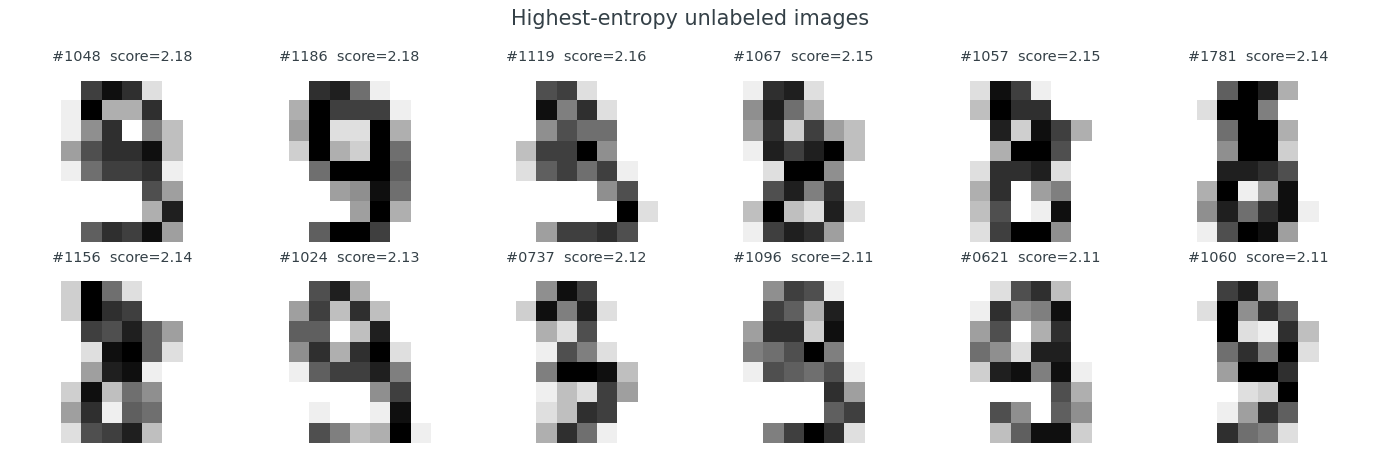

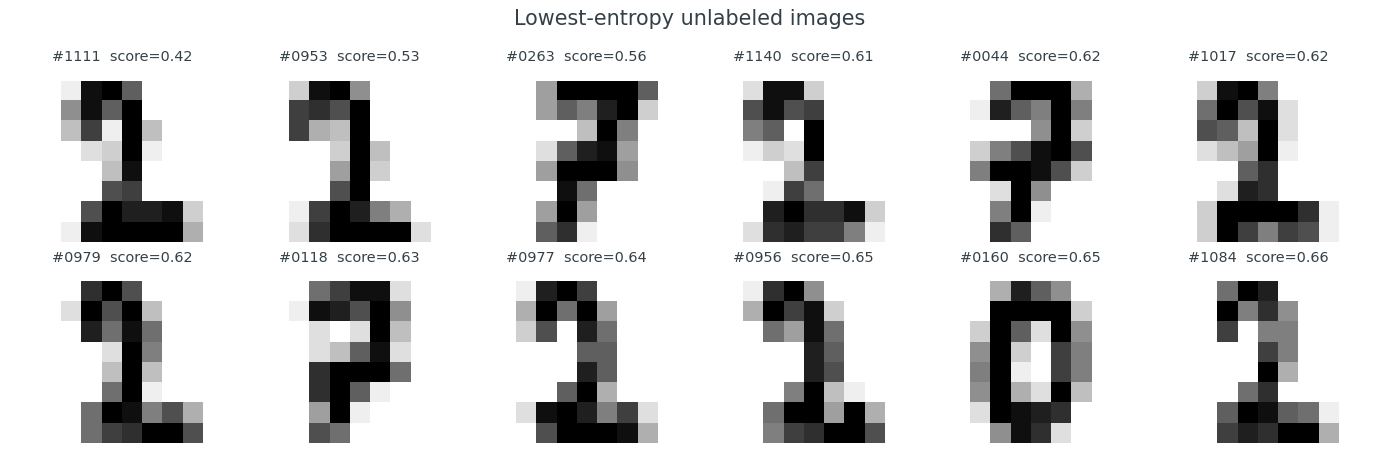

In [7]:
# Predict on the U0 candidate pool: no candidate labels are used here.
candidate_ids = sorted(baseline_pool.unlabeled_ids)
candidate_rows = np.asarray([id_to_index[oid] for oid in candidate_ids])
candidate_probabilities = baseline_model.predict_proba(X[candidate_rows])
candidate_predictions = ClassificationPredictions(
    candidate_probabilities, output_type="probabilities"
)
entropy_scores = EntropyScorer().score(candidate_predictions)
margin_scores = MarginScorer().score(candidate_predictions)
assert entropy_scores.shape == margin_scores.shape == (len(candidate_ids),)

def show_gallery(ids, title, scores=None, n=12):
    """Visualize selected objects by ID, without consulting hidden labels."""
    ids = list(ids)[:n]
    fig, axes = plt.subplots(2, 6, figsize=(12, 4))
    for ax, j in zip(axes.flat, range(12)):
        if j < len(ids):
            idx = id_to_index[ids[j]]
            ax.imshow(images[idx], cmap="gray_r", vmin=0, vmax=16)
            label = ids[j].replace("digit-", "#")
            if scores is not None:
                label += f"  score={float(scores[j]):.2f}"
            ax.set_title(label, fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

uncertain_order = np.argsort(-entropy_scores, kind="stable")
certain_order = np.argsort(entropy_scores, kind="stable")
show_gallery([candidate_ids[j] for j in uncertain_order[:12]],
             "Highest-entropy unlabeled images", entropy_scores[uncertain_order[:12]])
show_gallery([candidate_ids[j] for j in certain_order[:12]],
             "Lowest-entropy unlabeled images", entropy_scores[certain_order[:12]])


### TODO 1 — Reimplement predictive entropy (introductory)

Implement \`student_entropy(probabilities)\` without calling \`EntropyScorer\`. Use NumPy and support zero probabilities without computing $\log 0$. The function should accept an $N \times C$ array and return $N$ scores.

**Think:** Why is comparing raw logits with entropy mathematically incorrect? What is the maximum ten-class entropy?

The following exercise cell is **deliberately disabled by default**. Fill in the function, set \`RUN_EXERCISES=True\` in the first cell, and rerun the notebook to check your result.


In [8]:
def student_entropy(probabilities):
    """TODO 1: return an entropy score for every row (n_objects, n_classes)."""
    # TODO: implement safe -sum(p*log(p)), handling p=0 without log(0).
    return None


if RUN_EXERCISES:
    check_probabilities = np.array([[0.5, 0.5], [1.0, 0.0], [0.2, 0.8]])
    expected = EntropyScorer().score(
        ClassificationPredictions(check_probabilities, "probabilities")
    )
    np.testing.assert_allclose(student_entropy(check_probabilities), expected)
    print("Exercise 1 passed!")


### TODO 2 — Compare entropy and margin (intermediate)

Before implementing anything, inspect the first 20 object IDs favored by entropy and by margin. **Are they identical?** Try to explain any difference using a three-class counterexample where one distribution has a similar top-two gap but a very different third-class probability.

Then implement \`student_margin\`. Remember our “larger is better” ranking convention: return the **negative** top-two gap.


In [9]:
entropy_top = [candidate_ids[i] for i in np.argsort(-entropy_scores)[:20]]
margin_top = [candidate_ids[i] for i in np.argsort(-margin_scores)[:20]]
overlap = set(entropy_top) & set(margin_top)
print(f"Entropy/margin overlap in top 20: {len(overlap)}/20")
display(pd.DataFrame({"entropy_top": entropy_top, "margin_top": margin_top}))

def student_margin(probabilities):
    """TODO 2: negative gap between largest and second-largest class probability."""
    # TODO: implement the margin scorer in NumPy.
    return None


if RUN_EXERCISES:
    np.testing.assert_allclose(
        student_margin(candidate_probabilities[:50]),
        margin_scores[:50],
    )
    print("Exercise 2 passed!")


Entropy/margin overlap in top 20: 3/20


,entropy_top,margin_top
0,digit-1048,digit-0839
1,digit-1186,digit-0883
2,digit-1119,digit-0823
3,digit-1067,digit-1186
4,digit-1057,digit-1048
5,digit-1781,digit-1729
6,digit-1156,digit-0051
7,digit-1024,digit-0405
8,digit-0737,digit-0531
9,digit-1096,digit-1514


## 5. Ranking, selection, and pool transitions

An acquisition **scorer** produces one number per candidate. A **selector** enforces the budget and eligibility rules. Calling \`ActiveLearningLoop.query\` merely proposes a batch and does **not** change the pool. Calling \`acquire\` commits the choice by moving each object from **unlabeled → pending**.

An \`ExistingLabelsOracle\` is ideal for an offline teaching experiment: it keeps known labels inaccessible to the model until explicitly queried. Upon successful return, \`Pool.resolve\` moves the selected objects **pending → labeled**. Real oracles might respond slowly, fail, or return labels outside the taxonomy; those are important extensions, not assumptions silently baked into this toy case.

The short demonstration below uses its **own disposable pool**, so it cannot contaminate the later fair policy comparison.


After acquire: labeled = 50 pending = 8
After oracle + resolve: labeled = 58 pending = 0


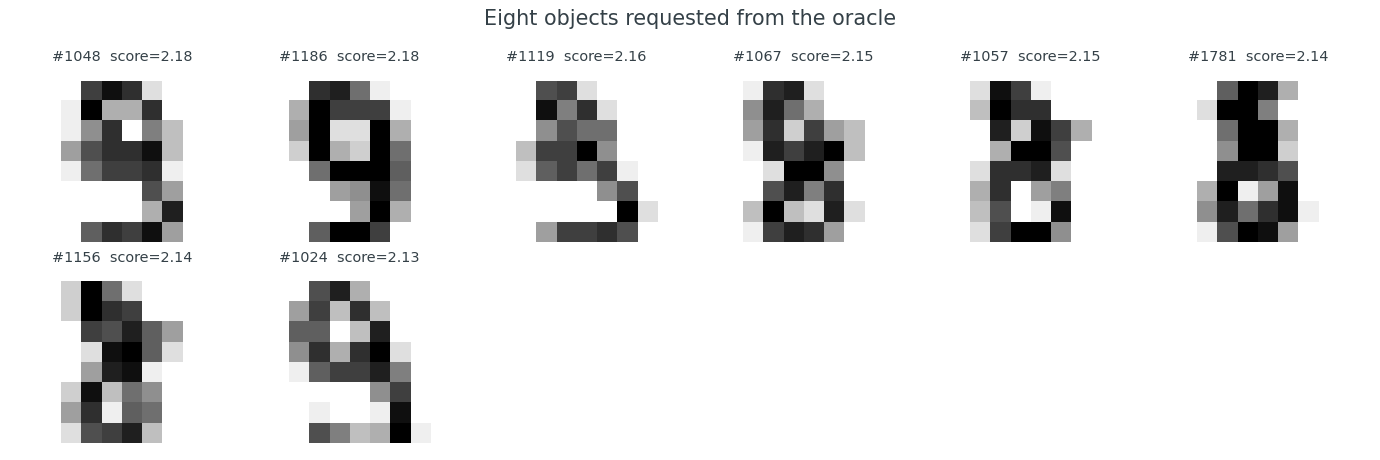

In [10]:
demo_pool = Pool.from_ids(pool_ids, labeled_ids=initial_ids)
demo_loop = ActiveLearningLoop(
    scorer=EntropyScorer(), selector=TopKSelector(), pool=demo_pool
)
proposal = demo_loop.query(
    ids=candidate_ids, acquisition_data=candidate_predictions, k=8
)
assert len(demo_pool.pending_ids) == 0  # querying is read-only
committed = demo_loop.acquire(
    ids=candidate_ids, acquisition_data=candidate_predictions, k=8
)
assert committed.ids == proposal.ids
assert set(committed.ids) == set(demo_pool.pending_ids)
print("After acquire: labeled =", len(demo_pool.labeled_ids),
      "pending =", len(demo_pool.pending_ids))
returned_labels = oracle.query(committed)
assert returned_labels.ids == committed.ids
demo_pool.resolve(returned_labels.ids)
assert len(demo_pool.pending_ids) == 0
assert len(demo_pool.labeled_ids) == 50 + 8
print("After oracle + resolve: labeled =", len(demo_pool.labeled_ids),
      "pending =", len(demo_pool.pending_ids))
show_gallery(committed.ids, "Eight objects requested from the oracle",
             scores=committed.scores)


## 6. Build the full closed loop

We can now assemble the experiment. A policy has its **own pool, observed labels, RNG and evaluation history**. Every policy starts with the identical $L_0$, train/validation split and classifier definition.

At each cycle we train a **new** logistic-regression instance on the cumulative observed labels. This is a restart-from-scratch comparison; it avoids introducing warm-start/checkpoint complexities into the first teaching exercise.

For random acquisition, \`RandomScorer\` receives a candidate count rather than model probabilities. Entropy and margin receive \`ClassificationPredictions\`. The optional diversity policy ranks by entropy first, then uses \`DiversitySelector\` to spread a batch across a shortlist in feature space.

**Audit invariant:** the training label dictionary equals the pool's labeled IDs. We never use test labels, and unlabeled ground truth enters the run only through \`oracle.query(selection)\`.


In [11]:
def run_active_learning(strategy, *, seed=SEED, acquisition_size=BATCH_SIZE,
                        n_cycles=N_CYCLES, verbose=False, initial_seed=None):
    """Run a self-contained acquisition trajectory; no ground truth leaks.

    Split and validation stay fixed. The default L0 is fixed; providing
    initial_seed selects a new balanced L0, shared by policies in a replicate.
    The seed argument separately controls random acquisition.
    The oracle holds candidate ground truth, but training observes labels
    exclusively via the initial L0 dictionary and oracle query responses.
    """
    if strategy not in {"random", "entropy", "margin", "entropy_diversity"}:
        raise ValueError(f"Unknown strategy: {strategy}")
    if acquisition_size < 1 or n_cycles < 0:
        raise ValueError("acquisition_size must be positive and n_cycles nonnegative")

    # Across main policies, keep the original identical L0. For the
    # repeated-seed exercise, vary L0 once per replicate and reuse it
    # for all policies being compared under that replicate.
    if initial_seed is None:
        run_initial_ids = list(initial_ids)
        run_initial_labels = dict(initial_labels)
    else:
        run_initial_ids, run_initial_labels = balanced_initial_population(initial_seed)
    assert len(run_initial_ids) == INITIAL_PER_CLASS * len(CLASS_LABELS)
    assert len(set(run_initial_ids)) == len(run_initial_ids)
    pool = Pool.from_ids(pool_ids, labeled_ids=run_initial_ids)
    observed_labels = dict(run_initial_labels)
    history = EvaluationHistory()
    acquired_ids_by_cycle = []
    selected_labels_by_cycle = []

    rng = np.random.default_rng(seed)
    selector = TopKSelector()  # replaced for entropy + diversity, per cycle
    if strategy == "random":
        scorer = RandomScorer(rng)
    elif strategy == "margin":
        scorer = MarginScorer()
    else:
        scorer = EntropyScorer()

    for cycle in range(n_cycles + 1):
        # Fit and record the model *before* requesting labels for this cycle.
        assert set(observed_labels) == set(pool.labeled_ids)
        assert not (set(pool.labeled_ids) & set(pool.unlabeled_ids))
        model = fit_model(observed_labels)
        metrics = evaluate_validation(model)

        history.add(
            cycle=cycle, n_labeled=len(pool.labeled_ids),
            n_acquired=0 if cycle == 0 else len(acquired_ids_by_cycle[-1]),
            split="validation", metrics=metrics,
            strategy=strategy, seed=seed, run_id=f"{strategy}-{seed}",
        )
        if verbose:
            print(f"{strategy:18s} cycle {cycle:2d}  L={len(pool.labeled_ids):3d}  "
                  f"macro-F1={metrics['f1_macro']:.3f}  "
                  f"balanced acc={metrics['balanced_accuracy']:.3f}")
        if cycle == n_cycles or not pool.unlabeled_ids:
            break

        ids = sorted(pool.unlabeled_ids)
        rows = np.array([id_to_index[oid] for oid in ids], dtype=int)
        if strategy == "random":
            acquisition_data = len(ids)
        else:
            acquisition_data = ClassificationPredictions(
                model.predict_proba(X[rows]), output_type="probabilities"
            )

        if strategy == "entropy_diversity":
            # Shortlist highest-entropy candidates, then greedily choose
            # diverse image representations within the shortlist.
            selector = DiversitySelector(X[rows], shortlist_multiplier=3.0)

        loop = ActiveLearningLoop(scorer=scorer, selector=selector, pool=pool)
        k = min(acquisition_size, len(ids))
        selection = loop.acquire(ids=ids, acquisition_data=acquisition_data, k=k)

        # Selected objects have become pending but are not yet training labels.
        assert set(selection.ids).issubset(pool.pending_ids)
        assert not (set(selection.ids) & set(observed_labels))

        received = oracle.query(selection)
        assert received.ids == selection.ids
        for oid, label in zip(received.ids, received.labels):
            observed_labels[oid] = int(label)
        pool.resolve(received.ids)
        assert not pool.pending_ids
        assert set(observed_labels) == set(pool.labeled_ids)

        acquired_ids_by_cycle.append(tuple(selection.ids))
        selected_labels_by_cycle.append(np.asarray(received.labels, dtype=int))

    return {
        "strategy": strategy,
        "seed": seed,
        "initial_seed": SEED if initial_seed is None else initial_seed,
        "initial_ids": tuple(run_initial_ids),
        "history": history,
        "pool": pool,
        "observed_labels": observed_labels,
        "acquired_ids_by_cycle": acquired_ids_by_cycle,
        "selected_labels_by_cycle": selected_labels_by_cycle,
        "model": model,
    }


In [12]:
# Run three policies with exactly the same train/validation split and L0.
STRATEGIES = ("random", "entropy", "margin")
results = {
    policy: run_active_learning(policy, verbose=False)
    for policy in STRATEGIES
}

summary = []
for policy, run in results.items():
    first = run["history"].records[0]
    last = run["history"].records[-1]
    assert first.n_labeled == INITIAL_PER_CLASS * len(CLASS_LABELS)
    assert last.n_labeled == first.n_labeled + BATCH_SIZE * N_CYCLES
    assert not run["pool"].pending_ids
    summary.append({
        "policy": policy,
        "initial_macro_f1": first.metrics["f1_macro"],
        "final_macro_f1": last.metrics["f1_macro"],
        "final_balanced_accuracy": last.metrics["balanced_accuracy"],
        "labels_acquired": last.n_labeled - first.n_labeled,
    })

summary_df = pd.DataFrame(summary)
display(summary_df.round(3))
assert len({round(row["initial_macro_f1"], 12) for row in summary}) == 1
print("All strategies began with the same L0 and acquired the same number of labels.")


,policy,initial_macro_f1,final_macro_f1,final_balanced_accuracy,labels_acquired
0,random,0.874,0.944,0.944,160
1,entropy,0.874,0.944,0.944,160
2,margin,0.874,0.963,0.964,160


All strategies began with the same L0 and acquired the same number of labels.


## 7. Visualize label efficiency—not just final accuracy

The meaningful horizontal axis is **how many labels the experiment has obtained**. Two strategies might achieve the same performance eventually but spend very different acquisition budgets getting there.

The package's \`EvaluationHistory\` stores metric values separately from training and selection, and \`plot_strategy_comparison\` draws the learning curves. We track both **macro-F1** and **balanced accuracy** on exactly the same fixed validation split.

> **Interpretation exercise:** Is entropy always superior to random acquisition? Is the best policy constant across all budgets? If the curves cross, what does “best” mean? A single trajectory is not enough evidence of a generally superior acquisition strategy.


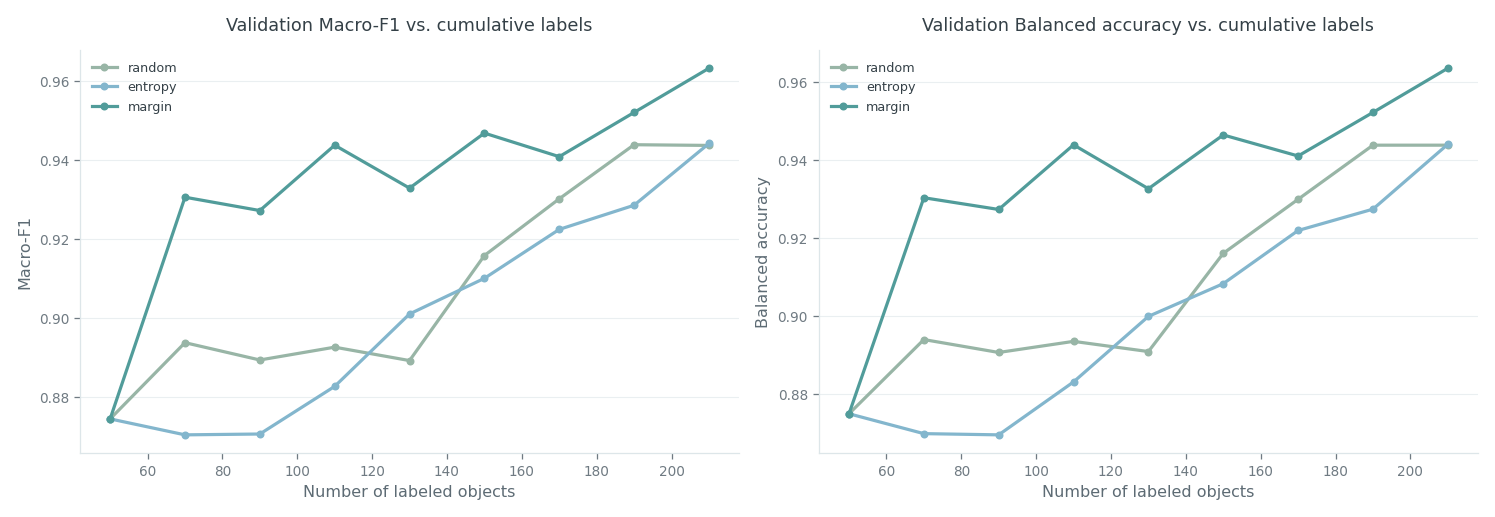

policy,entropy,margin,random
Total labeled objects,,,
50,0.874,0.874,0.874
70,0.870,0.931,0.894
90,0.870,0.927,0.889
110,0.883,0.944,0.893
130,0.901,0.933,0.889
150,0.910,0.947,0.916
170,0.922,0.941,0.930
190,0.929,0.952,0.944
210,0.944,0.963,0.944


In [13]:
# Use the built-in history plotting utility, after merging records from
# independent policy runs into a common display-only history.
combined_history = EvaluationHistory(
    [record for run in results.values() for record in run["history"].records]
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, label in zip(
    axes, ("f1_macro", "balanced_accuracy"),
    ("Macro-F1", "Balanced accuracy"),
):
    plot_strategy_comparison(
        combined_history, metric, split="validation",
        strategies=STRATEGIES, x_axis="n_labeled", ax=ax,
    )
    ax.set_ylabel(label)
    ax.set_title(f"Validation {label} vs. cumulative labels")
    polish_policy_axes(ax)
plt.tight_layout()
plt.show()

# A numerical companion to the plots makes every learning curve auditable
# and keeps the results inspectable even in a text-only export.
learning_curve = pd.DataFrame([
    {
        "policy": policy,
        "cycle": record.cycle,
        "n_labeled": record.n_labeled,
        "macro_f1": record.metrics["f1_macro"],
        "balanced_accuracy": record.metrics["balanced_accuracy"],
    }
    for policy, run in results.items()
    for record in run["history"].records
])
display(
    learning_curve.pivot(index="n_labeled", columns="policy", values="macro_f1")
    .rename_axis(index="Total labeled objects")
    .round(3)
)


### What kinds of objects are being acquired?

A high-uncertainty strategy often focuses on difficult examples, while a random baseline samples the eligible pool without looking at model probabilities. The next plots reveal **which** classes were acquired and **how much overlap** exists between policies.

The class distribution plot is an **audit performed after the oracle returned labels**. It is not an acquisition input. In particular, we do *not* use hidden class labels to enforce balancing of the unlabeled pool.


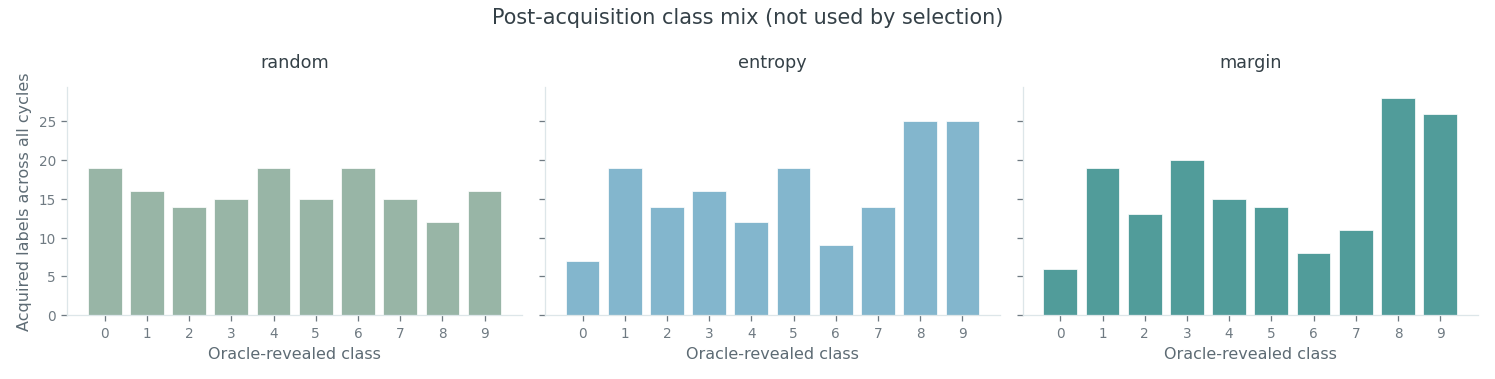

,random,entropy,margin
random,160,23,26
entropy,23,160,76
margin,26,76,160


Overlap is a descriptive post-hoc statistic; different policies do not need to acquire the same objects.


In [14]:
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(13, 3.3),
                         sharex=True, sharey=True)
for ax, policy in zip(axes, STRATEGIES):
    acquired_labels = np.concatenate(results[policy]["selected_labels_by_cycle"])
    counts = np.bincount(acquired_labels, minlength=len(CLASS_LABELS))
    ax.bar(CLASS_LABELS, counts, color=policy_color(policy), edgecolor="white")
    ax.set_title(policy)
    ax.set_xlabel("Oracle-revealed class")
    ax.set_xticks(CLASS_LABELS)
axes[0].set_ylabel("Acquired labels across all cycles")
fig.suptitle("Post-acquisition class mix (not used by selection)")
plt.tight_layout()
plt.show()

acquired_sets = {
    name: set(oid for batch in run["acquired_ids_by_cycle"] for oid in batch)
    for name, run in results.items()
}
overlap = np.array([
    [len(acquired_sets[a] & acquired_sets[b]) for b in STRATEGIES]
    for a in STRATEGIES
], dtype=int)
display(pd.DataFrame(overlap, index=STRATEGIES, columns=STRATEGIES))
print("Overlap is a descriptive post-hoc statistic; different policies "
      "do not need to acquire the same objects.")


## 8. The label budget is a real experimental constraint

When comparing strategies, hold the **same total number of newly revealed labels** fixed. If one policy buys 200 labels and another buys 40, their difference is not solely caused by the acquisition rule.

A large batch is queried before the model can be updated from any labels in that batch. Several small batches allow the model to react to newly revealed labels **more frequently**, but require more training cycles and potentially more human follow-up interactions.

Our core package provides \`plan_cycle_budget\` for exact final remainders and explicit partial-final-cycle rules. Below we demonstrate this budget planning.


In [15]:
from al_pipeline.core.experiments.budget import plan_cycle_budget

budget_plan = plan_cycle_budget(
    candidate_objects=len(pool_ids) - len(initial_ids),
    acquisition_size=BATCH_SIZE,
    max_cycles=N_CYCLES,
)
display(pd.DataFrame([{
    "planned_cycles": budget_plan.max_cycles,
    "total_new_labels": budget_plan.total_acquisitions,
    "last_cycle_size": budget_plan.final_cycle_size,
    "partial_final_cycle": budget_plan.allow_partial_final_cycle,
}]))
assert budget_plan.total_acquisitions == BATCH_SIZE * N_CYCLES


,planned_cycles,total_new_labels,last_cycle_size,partial_final_cycle
0,8,160,20,False


### TODO 3 — Same total labels, different batch sizes (intermediate)

Keep the **new-label budget fixed at 160**, but compare:
- 8 acquisition cycles × 20 labels;
- 16 acquisition cycles × 10 labels;
- 4 acquisition cycles × 40 labels.

All three runs should use **entropy**, an identical initial labeled population and the same validation split. Use `run_active_learning(...)` with different `acquisition_size` and `n_cycles` arguments. Plot validation macro-F1 against the **number of labeled objects** (not cycle number), and report how many model fits each schedule performs.

**Check:** each strategy should finish with 210 total labels, including the original 50. What does this exercise say about acquisition frequency and training cost?

Keep `RUN_OPTIONAL_EXPERIMENTS=False` while working through the notebook; set it to `True` when you've completed the following optional exercise cells. TODOs 1–2 can be tested separately using `RUN_EXERCISES=True` after implementing their functions.

In [16]:
if RUN_OPTIONAL_EXPERIMENTS:
    # TODO 3: run these three entropy schedules and compare their learning curves.
    batch_specs = {"8 x 20": (20, 8), "16 x 10": (10, 16), "4 x 40": (40, 4)}
    batch_experiments = None  # TODO: map each schedule name to a completed run

    # TODO: verify that all runs share the initial L0 and end at 210 labels.
    # TODO: plot validation macro-F1 against n_labeled, and report model fits.
    raise NotImplementedError("TODO 3: implement the batch-size comparison")

### TODO 4 — Repeat with paired initial populations (intermediate)

One curve does not establish that an acquisition policy consistently outperforms another. Repeat **random** and **entropy** with replication seeds 10, 20 and 30. For each seed, use `run_active_learning(..., seed=s, initial_seed=s)` so that each replicate begins from a new **balanced set of 50 labeled digits**. The *same* new initial population must be supplied to both policies within that replicate.

The train/validation/test split stays fixed. Entropy is deterministic given a model but **does vary when the initial labeled population changes**. Random acquisition additionally varies through its RNG. Therefore the observed variation reflects initial-L0 variability plus policy-specific randomness, not different split selections.

**Task:** plot mean validation macro-F1 and a band of ±1 **sample standard deviation** (`ddof=1`) across the three paired runs, on the same label-budget axis. Check that policy pairs share their starting ID sets, while different seeds have different starts. Why is pairing important?

In [17]:
if RUN_OPTIONAL_EXPERIMENTS:
    # TODO 4: compare random vs entropy over three PAIRED L0 replicates.
    replicate_seeds = (10, 20, 30)
    replicated = None  # TODO: policy -> list of completed runs, one per seed

    # TODO: check identical initial IDs across policies for each seed,
    #       but different initial IDs across seeds.
    # TODO: calculate per-budget mean and sample std; plot each policy
    #       with a shaded ±1 std band and report final-budget variation.
    raise NotImplementedError("TODO 4: implement paired repeated-seed comparison")

### TODO 5 — Why uncertainty can select redundant objects (advanced)

Entropy can assign high scores to several **similar** unlabeled images. Acquiring all of them may reveal less than choosing a varied batch of still-uncertain images.

Our `DiversitySelector` uses **farthest-first selection within a high-entropy shortlist**, after normalizing each feature vector. It encourages *within-batch* diversity; it is not a complete labeled-set core-set optimizer.

The reusable `run_active_learning` helper accepts `"entropy_diversity"`. Compare that approach against `results["entropy"]`, holding the original `L0`, the **160 newly acquired labels**, and the validation split fixed.

**Task:** plot macro-F1 learning curves, calculate overlap between the acquired object-ID sets, and show acquired **digit-class distributions** using labels returned by the oracle. Why might diversity help, and why might it hurt?

In [18]:
if RUN_OPTIONAL_EXPERIMENTS:
    # TODO 5: compare a diverse uncertain batch to the standard entropy batch.
    entropy_reference = results["entropy"]
    diversity_result = None  # TODO: run the entropy_diversity policy

    # TODO: verify equal budgets and initial sets.
    # TODO: compare macro-F1 curves and acquired-ID overlap.
    # TODO: plot acquired class counts using the revealed oracle labels.
    raise NotImplementedError("TODO 5: implement entropy + diversity comparison")

## 9. One final sealed-test evaluation

We used **validation** to compare policies. To illustrate proper final evaluation, we now select the policy with the highest *final validation macro-F1*, break ties alphabetically, and evaluate **one time** on the untouched test split.

This is a teaching demonstration, not a benchmark claim that the best strategy is universally better. In a real study, policy selection, seed replication, and final testing should be planned before examining test outcomes.

**Do not change a policy or its hyperparameters in response to the sealed-test result.**


In [19]:
winner = sorted(
    STRATEGIES,
    key=lambda p: (-results[p]["history"].records[-1].metrics["f1_macro"], p)
)[0]
winner_model = results[winner]["model"]
test_predictions = ClassificationPredictions(
    winner_model.predict_proba(X[test_indices]), output_type="probabilities"
)
final_test_metrics = compute_classification_metrics(
    y[test_indices], test_predictions, metrics=METRICS, labels=CLASS_LABELS
)
print(f"Selected from VALIDATION: {winner}")
display(pd.DataFrame([
    {"split": "validation", **results[winner]["history"].records[-1].metrics},
    {"split": "sealed test (once)", **final_test_metrics},
]).round(3))


Selected from VALIDATION: margin


,split,accuracy,balanced_accuracy,f1_macro
0,validation,0.964,0.964,0.963
1,sealed test (once),0.967,0.967,0.967


## 10. Wrap-up and further exercises

**What you should now be able to explain:**
1. Why $L_t$ and $U_t$ are separate, why IDs matter, and why labels move through a pending state.
2. Why a scorer (entropy or margin) is not a selector (top-k or diversity).
3. What the oracle simulates, and why the training model must not read the oracle's entire hidden mapping.
4. Why label budgets, an identical $L_0$, and fixed validation splits are essential for fair comparison.
5. Why repeated seeds, sample diversity and calibration can complicate a simple uncertainty-sampling story.

**Optional discussion questions (no extra code required):**
- What happens if 20% of oracle queries cannot be resolved? Should they remain pending or return to $U_t$?
- What changes if some labels are expensive and others are cheap? Should budgets count objects or cost?
- Could an uncertain image be an outlier, corrupted observation, or a class outside the current taxonomy?
- How would your design change if one astronomical object generates multiple alerts over time?

**AppleCiDEr connection:** replace images with alert features, the digit classifier with an appropriate astronomical model, and the simulated oracle with a validated evidence/resolution process. The domain-agnostic scoring, selection, budget and pool concepts remain recognizable. Those integrations are intentionally beyond the scope of this introductory notebook.

**About the exercises:** all five TODOs are intentionally unsolved in this participant notebook. The core demonstration has been executed, and its figures are provided for reference. Complete each TODO yourself, then enable the relevant exercise flag to check or run it.
